In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# IMPORT
import sys
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torch.utils.data import random_split
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset
import numpy as np
import os
import torch
import torch.nn as nn
import torch.optim as optim
import copy
import re
import torch
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
import os
import matplotlib.pyplot as plt



root_path = "/content/drive/MyDrive/Action Recognition on UCF101"
src_path = os.path.join(root_path, "src")
split_path = os.path.join(root_path, "ucfTrainTestlist")

if src_path not in sys.path:
    sys.path.append(src_path)

#from dataset import UCF101Dataset
#from dataset import get_datasets
from dataset2 import UCF101DatasetFast
from dataset2 import get_datasets
from models import ResNet2D_Baseline, CustomCNN, ResNet2D_LSTM, ResNet2D_BiLSTM_Pro
from training import validate, get_next_run_id

In [ ]:
annotation_file_train=os.path.join(split_path, "trainlist01.txt")
annotation_file_test=os.path.join(split_path, "testlist01.txt")
class_ind_file=os.path.join(split_path, "classInd.txt")

In [ ]:
zip_path_drive = "/content/drive/MyDrive/Action Recognition on UCF101/UCF-101-JPG-zipped.zip"
local_root = "/content/data"
final_data_path = os.path.join(local_root, "temp_jpg_224")
if not os.path.exists(final_data_path):

    os.makedirs(local_root, exist_ok=True)

    !unzip -q -o "{zip_path_drive}" -d "{local_root}"

    print(f"Done! Data ready in: {final_data_path}")
else:
    print(f"Data already in {final_data_path}.")

# VERIFY
if os.path.exists(final_data_path):
    num_classes = len(os.listdir(final_data_path))
    print(f"Found {num_classes} classes in {final_data_path}")
else:
    print("Something gone wrong. Check zip name or path.")

Done! Data ready in: /content/data/temp_jpg_224
Found 101 classes in /content/data/temp_jpg_224


In [ ]:
# HYPERPARAMETERS
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 16
NUM_CLASSES = 101
FRAMES = 16

print(f"Using device: {DEVICE}")

Using device: cuda


In [ ]:
data_root="/content/data/temp_jpg_224"
annotation_file_train=os.path.join(split_path, "trainlist01.txt")
annotation_file_test=os.path.join(split_path, "testlist01.txt")
class_ind_file=os.path.join(split_path, "classInd.txt")
config = {
    "DATA_ROOT" : data_root,
    "TRAIN_ANNOTATION_FILE": annotation_file_train,
    "TEST_ANNOTATION_FILE" : annotation_file_test,
    "CLASS_IND_FILE": class_ind_file,
    "FRAMES_PER_CLIP":16,
    "RESIZE_HEIGHT" : 224,
    "RESIZE_WIDTH" : 224
}
print("Loading Datasets...")
train_dataset, val_dataset, test_dataset = get_datasets(config)

Loading Datasets...
--------------------------------------------------
GROUP-BASED SPLIT SUMMARY:
Train samples: 7675, ['JumpingJack_g17', 'RopeClimbing_g22', 'HighJump_g18', 'MoppingFloor_g12', 'PlayingFlute_g08', 'Nunchucks_g17', 'MilitaryParade_g23', 'UnevenBars_g23', 'HighJump_g22', 'WritingOnBoard_g23', 'Archery_g11', 'TennisSwing_g14', 'HeadMassage_g18', 'ApplyLipstick_g09', 'Kayaking_g17', 'BabyCrawling_g10', 'Swing_g10', 'CricketShot_g09', 'ApplyEyeMakeup_g21', 'RockClimbingIndoor_g20', 'FrisbeeCatch_g11', 'HorseRace_g09', 'RockClimbingIndoor_g21', 'PoleVault_g25', 'HorseRiding_g15', 'VolleyballSpiking_g20', 'FrisbeeCatch_g17', 'HorseRiding_g12', 'TaiChi_g08', 'WalkingWithDog_g12', 'BlowDryHair_g25', 'CricketBowling_g25', 'PoleVault_g15', 'IceDancing_g23', 'TaiChi_g17', 'CleanAndJerk_g25', 'VolleyballSpiking_g14', 'BreastStroke_g21', 'YoYo_g13', 'BreastStroke_g15', 'YoYo_g22', 'Diving_g17', 'BoxingSpeedBag_g19', 'FrisbeeCatch_g08', 'PlayingDhol_g22', 'PlayingGuitar_g20', 'Socce

In [ ]:
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2) # Shuffle False per Val
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0
    from tqdm import tqdm
    loop = tqdm(loader, desc="Training")

    for batch_videos, batch_labels in loop:

        videos = batch_videos.to(device)
        labels = batch_labels.to(device)


        optimizer.zero_grad()


        outputs = model(videos)
        loss = criterion(outputs, labels)


        loss.backward()

        # GRADIENT CLIPPING
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        loop.set_postfix(loss=loss.item(), acc=100 * correct / total)

    avg_loss = running_loss / total
    avg_acc = 100 * correct / total

    return avg_loss, avg_acc

 EXPERIMENT STARTED: ResNet2D_BiLSTM
 MODE: End-to-End Fine-Tuning (ImageNet weights)
 OUTPUT FOLDER: /content/drive/MyDrive/Action Recognition on UCF101/experiments/ResNet2D_BiLSTM/Run_03
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 170MB/s]



Starting Training loop...
Epoch 1/50


Validation: 100%|██████████| 117/117 [00:39<00:00,  2.95it/s]


 -> Train Loss: 3.9283 | Acc: 13.67%
 -> Val Loss:   2.8744 | Acc: 38.67%
    >>> New Best Validation Accuracy! Model saved.
Epoch 2/50


Validation: 100%|██████████| 117/117 [00:41<00:00,  2.85it/s]


... (43 outputs left out)

Validation: 100%|██████████| 117/117 [00:41<00:00,  2.85it/s]


 -> Train Loss: 0.8215 | Acc: 99.92%
 -> Val Loss:   1.6400 | Acc: 77.07%
!!! No improvement. Patience: 14/15
Epoch 25/50


Validation: 100%|██████████| 117/117 [00:40<00:00,  2.91it/s]


 -> Train Loss: 0.8209 | Acc: 99.95%
 -> Val Loss:   1.6436 | Acc: 77.77%
!!! No improvement. Patience: 15/15

EARLY STOPPING TRIGGERED.

 TRAINING COMPLETE
Generating training plots...


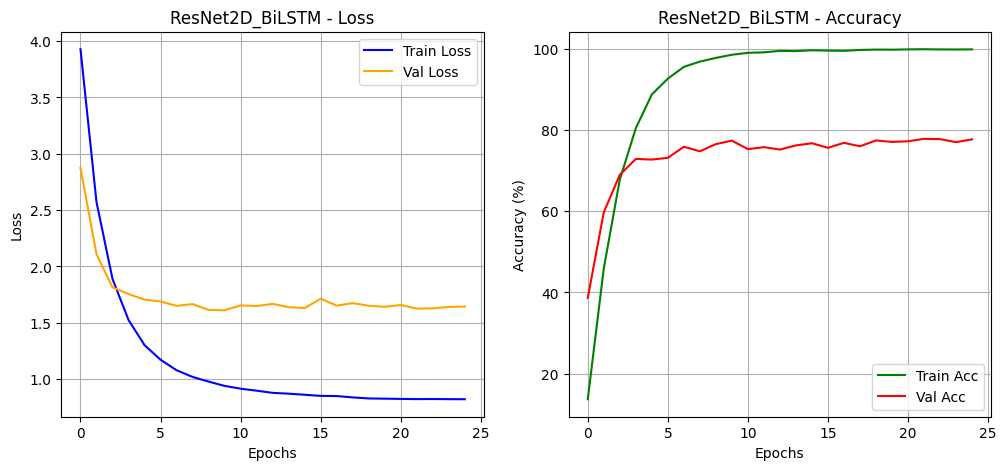

In [9]:
# --- Configuration ---
VARIANT_NAME = "ResNet2D_BiLSTM"
EXPERIMENTS_ROOT = os.path.join(root_path, "experiments", VARIANT_NAME)
RUN_ID = get_next_run_id(EXPERIMENTS_ROOT)
checkpoint_dir = os.path.join(EXPERIMENTS_ROOT, RUN_ID)
best_model_path = os.path.join(checkpoint_dir, "best_model.pth")

os.makedirs(checkpoint_dir, exist_ok=True)

PATIENCE = 15
EARLY_STOPPING_DELTA = 0.001
LEARNING_RATE_CNN = 1e-5
LEARNING_RATE_LSTM = 1e-4
NUM_EPOCHS = 50

print(f"==================================================")
print(f" EXPERIMENT STARTED: {VARIANT_NAME}")
print(f" MODE: End-to-End Fine-Tuning (ImageNet weights)")
print(f" OUTPUT FOLDER: {checkpoint_dir}")
print(f"==================================================")


model = ResNet2D_BiLSTM_Pro(
    num_classes=NUM_CLASSES,
    lstm_hidden_size=512,
    dropout_rate=0.6
).to(DEVICE)

# Optimizer with Differential Learning Rates
optimizer = optim.AdamW([
    {'params': model.feature_extractor.parameters(), 'lr': LEARNING_RATE_CNN},
    {'params': model.lstm.parameters(), 'lr': LEARNING_RATE_LSTM},
    {'params': model.classifier.parameters(), 'lr': LEARNING_RATE_LSTM}
], weight_decay=1e-4)

# Scheduler
# It will reduce the LR by factor 0.1 if the val_loss doesn't improve for 5 epochs
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=7)

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

train_loss_hist, val_loss_hist = [], []
train_acc_hist, val_acc_hist = [], []

best_val_acc = 0.0
min_val_loss = float('inf')
early_stopping_counter = 0

print(f"\nStarting Training loop...")

for epoch in range(NUM_EPOCHS):
    print(f"Epoch {epoch+1}/{NUM_EPOCHS}")

    # TRAIN STEP
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)

    # VALIDATION STEP
    val_loss, val_acc = validate(model, val_loader, criterion, DEVICE)

    # Update Scheduler
    scheduler.step(val_loss)

    train_loss_hist.append(train_loss)
    val_loss_hist.append(val_loss)
    train_acc_hist.append(train_acc)
    val_acc_hist.append(val_acc)

    print(f" -> Train Loss: {train_loss:.4f} | Acc: {train_acc:.2f}%")
    print(f" -> Val Loss:   {val_loss:.4f} | Acc: {val_acc:.2f}%")


    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), best_model_path)
        print(f"    >>> New Best Validation Accuracy! Model saved.")

    if val_loss < (min_val_loss - EARLY_STOPPING_DELTA):
        min_val_loss = val_loss
        early_stopping_counter = 0
    else:
        early_stopping_counter += 1
        print(f"!!! No improvement. Patience: {early_stopping_counter}/{PATIENCE}")
        if early_stopping_counter >= PATIENCE:
            print(f"\nEARLY STOPPING TRIGGERED.")
            break


print("\n" + "="*50)
print(" TRAINING COMPLETE")
print("="*50)

print("Generating training plots...")

plt.figure(figsize=(12, 5))

# Plot Loss
plt.subplot(1, 2, 1)
plt.plot(train_loss_hist, label='Train Loss', color='blue')
plt.plot(val_loss_hist, label='Val Loss', color='orange')
plt.title(f'{VARIANT_NAME} - Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot Accuracy
plt.subplot(1, 2, 2)
plt.plot(train_acc_hist, label='Train Acc', color='green')
plt.plot(val_acc_hist, label='Val Acc', color='red')
plt.title(f'{VARIANT_NAME} - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

plt.show()

In [10]:
# Check the first 10 labels of the test set
test_labels = [test_dataset.samples[i][1] for i in range(10)]
unique_test_labels = set([s[1] for s in test_dataset.samples])

print(f"First 10 test labels: {test_labels}")
print(f"Number of unique classes in test set: {len(unique_test_labels)}")
print(f"Unique labels found: {unique_test_labels}")

First 10 test labels: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Number of unique classes in test set: 1
Unique labels found: {0}


In [11]:
# RECOVER CLASS MAPPING
class_to_idx = {}

for path, label in train_dataset.samples:
    class_name = os.path.basename(os.path.dirname(path))
    class_to_idx[class_name] = label

print(f"Mapping reconstructed for {len(class_to_idx)} classes.")

# APPLY MAPPING TO TEST DATASET (REPAIR)
# This step ensures that the test labels are synchronized with the training labels
repaired_samples = []
for path, old_label in test_dataset.samples:
    class_name = os.path.basename(os.path.dirname(path))

    if class_name in class_to_idx:
        new_label = class_to_idx[class_name]
        repaired_samples.append((path, new_label))
    else:
        # Fallback: keep the original label if the class is not found in the training set
        repaired_samples.append((path, old_label))

# Update the test dataset samples with the corrected labels
test_dataset.samples = repaired_samples

# FINAL VERIFICATION
unique_labels = set([s[1] for s in test_dataset.samples])
print(f"Verification complete: Found {len(unique_labels)} unique classes in the Test Set.")

Mapping reconstructed for 101 classes.
Verification complete: Found 101 unique classes in the Test Set.


In [12]:
def perform_final_evaluation(model, test_loader, best_model_path, train_dataset, device):
    print("--- STARTING FINAL EXTENDED EVALUATION ---")

    idx_to_class = {}
    for path, label in train_dataset.samples:
        class_name = os.path.basename(os.path.dirname(path))
        if label not in idx_to_class:
            idx_to_class[label] = class_name


    model.load_state_dict(torch.load(best_model_path))
    model.to(device)
    model.eval()

    all_preds = []
    all_labels = []

    print("Running inference on test set...")
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)


    final_acc = (all_preds == all_labels).mean() * 100
    print(f"\nFINAL TEST ACCURACY: {final_acc:.2f}%")
    print("-" * 40)


    target_names = [idx_to_class[i] for i in sorted(idx_to_class.keys())]
    full_report = classification_report(all_labels, all_preds, target_names=target_names, digits=4)
    print("\nCLASSIFICATION REPORT:")
    print(full_report)


    cm = confusion_matrix(all_labels, all_preds)
    per_class_acc = np.divide(cm.diagonal(), cm.sum(axis=1),
                              out=np.zeros_like(cm.diagonal(), dtype=float),
                              where=cm.sum(axis=1)!=0)


    performance_df = pd.DataFrame({
        'Class_Name': [idx_to_class.get(i, f"Unknown_{i}") for i in range(len(per_class_acc))],
        'Accuracy': per_class_acc
    }).sort_values(by='Accuracy', ascending=True)

    print("\nTOP 5 MOST DIFFICULT CLASSES (Lowest Accuracy):")

    print(performance_df.head(5).to_string(index=False, formatters={'Accuracy': '{:,.2%}'.format}))

    print("\nTOP 5 BEST PERFORMING CLASSES (Highest Accuracy):")
    print(performance_df.tail(5).sort_values(by='Accuracy', ascending=False).to_string(index=False, formatters={'Accuracy': '{:,.2%}'.format}))

    return all_labels, all_preds, performance_df

labels, preds, class_stats = perform_final_evaluation(model, test_loader, best_model_path, train_dataset, DEVICE)

--- STARTING FINAL EXTENDED EVALUATION ---
Running inference on test set...

FINAL TEST ACCURACY: 78.14%
----------------------------------------

CLASSIFICATION REPORT:
                    precision    recall  f1-score   support

    ApplyEyeMakeup     0.9062    0.6591    0.7632        44
     ApplyLipstick     0.6279    0.8438    0.7200        32
           Archery     0.6522    0.7317    0.6897        41
      BabyCrawling     0.8529    0.8286    0.8406        35
       BalanceBeam     0.9333    0.9032    0.9180        31
      BandMarching     0.8571    0.9767    0.9130        43
     BaseballPitch     0.8378    0.7209    0.7750        43
        Basketball     0.5682    0.7143    0.6329        35
    BasketballDunk     1.0000    1.0000    1.0000        37
        BenchPress     0.8571    1.0000    0.9231        48
            Biking     0.8947    0.8947    0.8947        38
         Billiards     1.0000    1.0000    1.0000        40
       BlowDryHair     0.7561    0.8158    0.7848